# plutovizu — Prise en main : courbes, barres, nuages de points

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

## Données d'exemple

In [2]:
rng = np.random.default_rng(42)
n = 120
jours = np.arange(n)
effet_categorie = {'A': 150, 'B': -80, 'C': 40, 'D': -150}

ventes = pd.DataFrame({
    'date': pd.date_range('2024-01-01', periods=n, freq='D'),
    'categorie': rng.choice(list(effet_categorie), n),
    'temperature': rng.normal(27, 4, n).round(1),
})
# tendance + cycle mensuel + effet de la catégorie + bruit
ventes['ventes'] = (np.linspace(900, 1300, n) + 120 * np.sin(jours * 2 * np.pi / 30)
                    + ventes['categorie'].map(effet_categorie) + rng.normal(0, 40, n))
ventes['profit'] = ventes['ventes'] * 0.18 + rng.normal(0, 15, n)
ventes['visiteurs'] = (20 + 2.2 * ventes['temperature'] + rng.normal(0, 6, n)).round().astype(int)
ventes.head()

,date,categorie,temperature,ventes,profit,visiteurs
0,2024-01-01,A,23.5,1045.254467,161.794977,71
1,2024-01-02,D,30.9,789.743793,147.073815,96
2,2024-01-03,C,20.3,1047.771156,214.509061,65
3,2024-01-04,B,25.7,909.393564,140.682920,72
4,2024-01-05,B,27.7,906.185668,176.070840,77


## Courbes

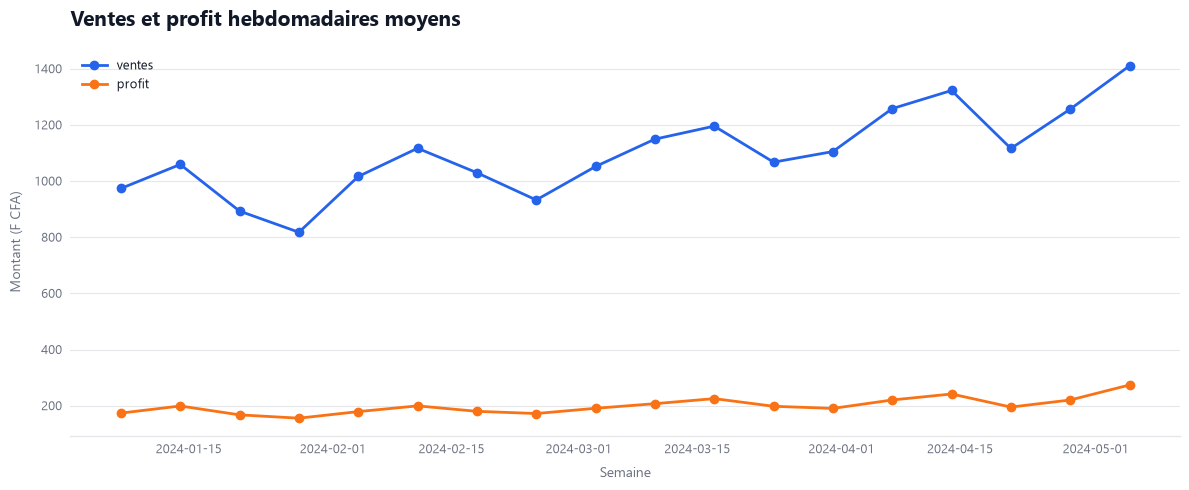

In [3]:
hebdo = ventes.resample('W', on='date')[['ventes', 'profit']].mean().reset_index()

(Chart(hebdo, figsize=(12, 5))
    .line('date', ['ventes', 'profit'])
    .title('Ventes et profit hebdomadaires moyens')
    .labels(xlabel='Semaine', ylabel='Montant (F CFA)')
    .grid()
    .set_legend()
    .tight_layout()
    .show())

## Barres

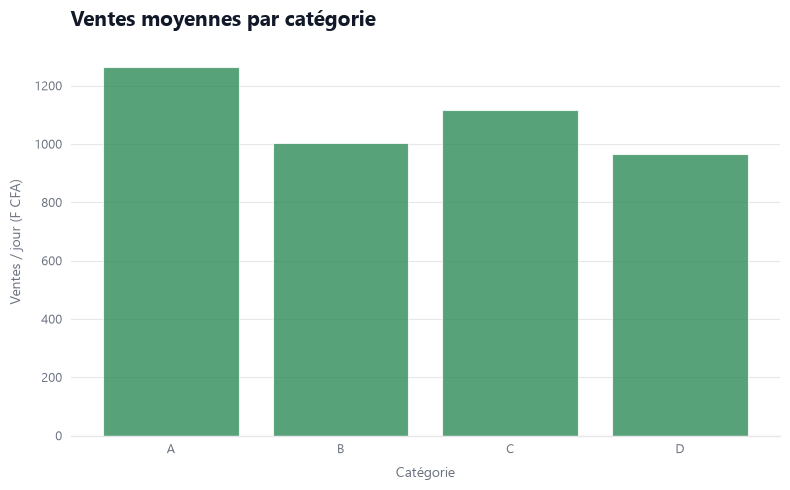

In [4]:
par_categorie = ventes.groupby('categorie', as_index=False)['ventes'].mean()

(Chart(par_categorie, figsize=(8, 5))
    .bar('categorie', 'ventes', color='seagreen')
    .title('Ventes moyennes par catégorie')
    .labels(xlabel='Catégorie', ylabel='Ventes / jour (F CFA)')
    .tight_layout()
    .show())

Plusieurs colonnes `y` donnent des barres groupées, ou empilées avec `stacked=True` ; `show_values=True` écrit les valeurs.

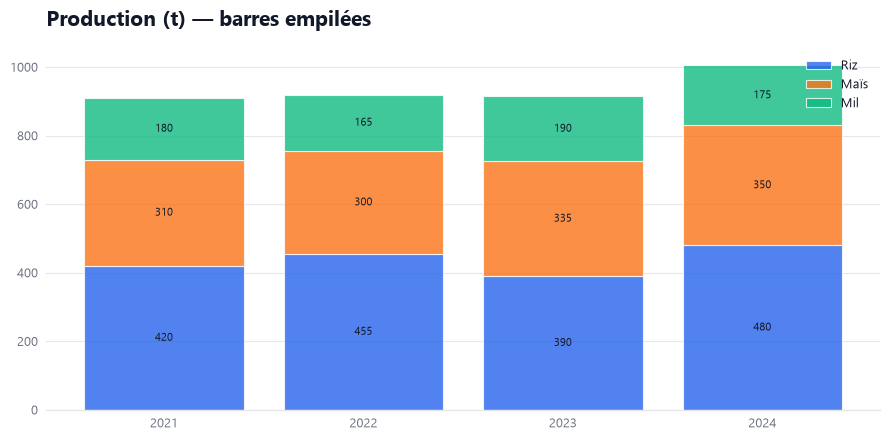

In [5]:
production = pd.DataFrame({'annee': ['2021', '2022', '2023', '2024'],
                           'Riz': [420, 455, 390, 480], 'Maïs': [310, 300, 335, 350],
                           'Mil': [180, 165, 190, 175]})

(Chart(production, figsize=(9, 4.5))
    .bar('annee', ['Riz', 'Maïs', 'Mil'], stacked=True, show_values=True)
    .title('Production (t) — barres empilées')
    .tight_layout()
    .show())

## Nuage de points

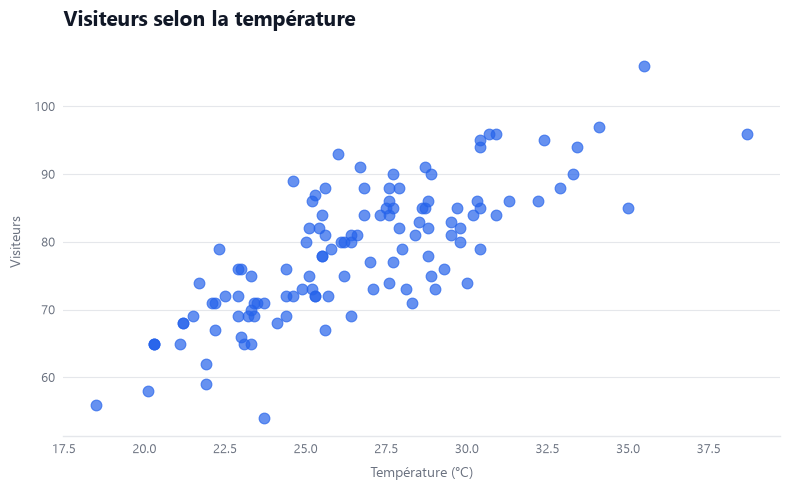

In [6]:
(Chart(ventes, figsize=(8, 5))
    .scatter('temperature', 'visiteurs', size=60)
    .title('Visiteurs selon la température')
    .labels(xlabel='Température (°C)', ylabel='Visiteurs')
    .grid()
    .tight_layout()
    .show())